In [16]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [17]:
raw_data=pd.read_excel(r'C:\Users\Jose.Hurtado\Downloads\Export.xlsx')
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2630 entries, 0 to 2629
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  2630 non-null   str  
 1   Message  2630 non-null   str  
 2   Status   2630 non-null   str  
dtypes: str(3)
memory usage: 61.8 KB


In [18]:
aux=pd.DataFrame()
aux=raw_data
aux['Headers']='NaN'

for i in range(0,aux.shape[0]):
    aux.iloc[i,3]=aux.iloc[i,2][0:8]

aux['Headers'].value_counts()

Headers
0x252513    2487
0x252501      85
0x252511      58
Name: count, dtype: int64

In [19]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2630 entries, 0 to 2629
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  2630 non-null   str  
 1   Message  2630 non-null   str  
 2   Status   2630 non-null   str  
 3   Headers  2630 non-null   str  
dtypes: str(4)
memory usage: 82.3 KB


Odometer

In [20]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux['Odometer in meters']=0.0
odometer=[]
date=[]
raw=[]
unit=pd.DataFrame()

for i in range(0,unit_aux.shape[0]):
    odometer.append(int(unit_aux.iloc[i,2][96:104],16))
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Odometer in meters']=odometer
unit_aux['Date']=date
unit_aux['Raw data']=raw

#print(unit_aux['Odometer in meters'])

unit=unit_aux.sort_values('Date',ascending=True)

print(unit.info())

<class 'pandas.DataFrame'>
Index: 2487 entries, 0 to 2629
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Created             2487 non-null   str  
 1   Message             2487 non-null   str  
 2   Status              2487 non-null   str  
 3   Headers             2487 non-null   str  
 4   Odometer in meters  2487 non-null   int64
 5   Date                2487 non-null   str  
 6   Raw data            2487 non-null   str  
dtypes: int64(1), str(6)
memory usage: 155.4 KB
None


261101000032 -> 0 -> 678145.0 -> 0x252513005921DD0869487064430621007800782D000000440000000000000061000000FFFFFFFFFFFFFFFFFFFF00D5000A59010026110100003282CC000A09078CCB37F100960096009603901395FFFFFF00001EFFFFFFFFFF
261101000232 -> 1 -> 678145.0 -> 0x252513005921DE0869487064430621007800782D000000590000000000000061000000FFFFFFFFFFFFFFFFFFFF00D5000A59019926110100023282CC000A0901F05B37F10065018E00F703891395FFFFFF00001EFFFFFFFFFF
261101000432 -> 2 -> 678145.0 -> 0x252513005921DF0869487064430621007800782D0000004B0000000000000061000000FFFFFFFFFFFFFFFFFFFF00D5000A59019826110100043282CC000A0901F05C37F1012700B900B703891394FFFFFF00001EFFFFFFFFFF
261101000631 -> 3 -> 678145.0 -> 0x252513005921E00869487064430621007800782D0000003A0000000000000061000000FFFFFFFFFFFFFFFFFFFF00D5000A59019826110100063182CC000A0901F05C37F1012700B700B903891391FFFFFF00001EFFFFFFFFFF
261101000831 -> 4 -> 678145.0 -> 0x252513005921E10869487064430621007800782D000000640000000000000061000000FFFFFFFFFFFFFFFFFFFF00D5000A59019926110

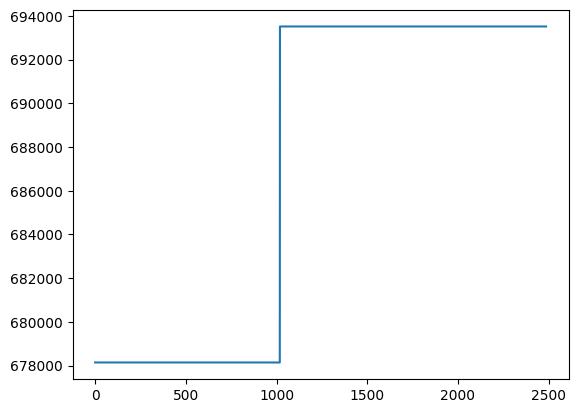

In [21]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,4]))
    x_axis.append(i)
    date.append(unit.iloc[i,5])
    raw_data_.append(unit.iloc[i,6])

#print("Delta odometer: ",y_axis[170]-y_axis[133],'meters')

for i in range(0,len(odometer)):
    print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

#print(odometer[len(odometer)-1]-odometer[0])
plt.plot(x_axis,y_axis)

Speed

In [22]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
#unit_aux['Odometer in meters']=0.0
speed=[]
date=[]
raw=[]
unit_speed=pd.DataFrame()
unit=pd.DataFrame()

for i in range(0,unit_aux.shape[0]):
    try:
        lbs_ind=(bin(int(unit_aux.iloc[i,2][50:52],16) & 64))
        if lbs_ind=='0b1000000':
            speed.append(int(unit_aux.iloc[i,2][142:145]))  
            date.append(unit_aux.iloc[i,2][106:118])
            raw.append(unit_aux.iloc[i,2])
            #print(lbs_ind)

    except:
        pass    

unit_speed['Speed']=speed
unit_speed['Date']=date
unit_speed['Raw data']=raw

unit=unit_speed.sort_values('Date',ascending=True)

print(unit.info())

<class 'pandas.DataFrame'>
Index: 116 entries, 0 to 115
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Speed     116 non-null    int64
 1   Date      116 non-null    str  
 2   Raw data  116 non-null    str  
dtypes: int64(1), str(2)
memory usage: 3.6 KB
None


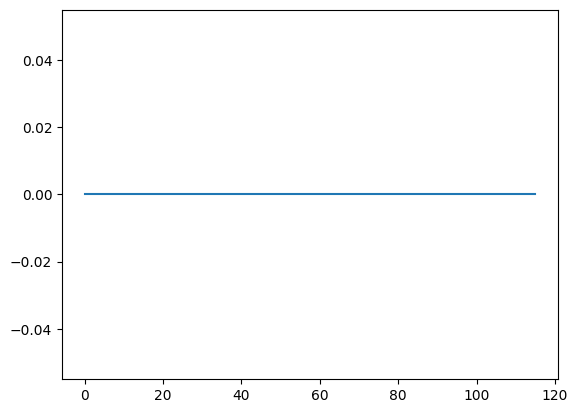

In [23]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,0]))
    x_axis.append(i)
    date.append(unit.iloc[i,1])
    raw_data_.append(unit.iloc[i,2])
    #print(raw_data_[i])

for i in range(0,len(speed)):
    if (y_axis[i]>55):
        print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

plt.plot(x_axis,y_axis)

Satellites

In [24]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
satellite_number=[]
satellite_connection_indicator=[]
date=[]
raw=[]
num_events=0

for i in range(0,unit_aux.shape[0]):
    satellite_number.append(int(unit_aux.iloc[i,2][50:52],16) & 31)
    satellite_connection_indicator.append(int(unit_aux.iloc[i,2][50:52],16) & 128)
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Satellites']=satellite_number
unit_aux['Satellite_connection_indicator']=satellite_connection_indicator
unit_aux['Raw data']=raw
unit_aux['date']=date

unit=unit_aux.sort_values('date',ascending=True)
unit.info()

for i in range(0,unit.shape[0]):
    if unit.iloc[i,4]<1:
        num_events=num_events+1
        print(unit.iloc[i,0], '->',unit.iloc[i,4],'->',unit.iloc[i,5],'->',unit.iloc[i,6])

print("Eventos históricos: ",num_events)

<class 'pandas.DataFrame'>
Index: 2487 entries, 0 to 2629
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   Created                         2487 non-null   str  
 1   Message                         2487 non-null   str  
 2   Status                          2487 non-null   str  
 3   Headers                         2487 non-null   str  
 4   Satellites                      2487 non-null   int64
 5   Satellite_connection_indicator  2487 non-null   int64
 6   Raw data                        2487 non-null   str  
 7   date                            2487 non-null   str  
dtypes: int64(2), str(6)
memory usage: 174.9 KB
2026-11-01 00:00:32.947 -> 0 -> 0 -> 0x252513005921DD0869487064430621007800782D000000440000000000000061000000FFFFFFFFFFFFFFFFFFFF00D5000A59010026110100003282CC000A09078CCB37F100960096009603901395FFFFFF00001EFFFFFFFFFF
2026-11-01 00:02:33.160 -> 0 -> 0 -> 0x252513005921DE0

In/Outs

15      14                 13      12      11      10      09      08       07 06 05 04 03 02 01 00
Power   Ignition/Input0    Input1  Input2  Input3  Input4  Input5  Input0

15=0, Connected
15=1. Disconnected

In [25]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux.info()
aux_cad=[]
aux_date=[]
aux_raw_data=[]
aux_input_number=[]
in_outs=[]

#unit_aux.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sym\concatenated.csv')

for i in range(0,unit_aux.shape[0]):
    long_cad=len(unit_aux.iloc[i,2])
    if ((long_cad>48) & (long_cad<204)):
        aux_cad.append(unit_aux.iloc[i,2])   

for i in range(0,len(aux_cad)):
    aux_value=aux_cad[i][64:68]
    aux_date.append(aux_cad[i][106:118])
    aux_raw_data.append(aux_cad[i])
    in_outs.append(bin (int (aux_cad[i][64:68],16)))      

unit_=pd.DataFrame()
unit_['in and outs']=in_outs
unit_['date']=aux_date
unit_['raw data']=aux_raw_data

in_outs_df=unit_.sort_values('date',ascending=True)

in_outs_df.to_csv(r'C:\Users\Jose.Hurtado\Downloads\in_outs_df.csv')

<class 'pandas.DataFrame'>
Index: 2487 entries, 0 to 2629
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  2487 non-null   str  
 1   Message  2487 non-null   str  
 2   Status   2487 non-null   str  
 3   Headers  2487 non-null   str  
dtypes: str(4)
memory usage: 97.1 KB


Ignition

In [26]:
in_outs_df.info()

for i in range(0,in_outs_df.shape[0]):
    length=len(in_outs_df.iloc[i,0])
    if length>16:
        aux_ign=in_outs_df.iloc[i,0][2:3]
        if aux_ign=='1':
            print("Ignition On",in_outs_df.iloc[i,0])
        if aux_ign=='0':
            print("Ignition Off",in_outs_df.iloc[i,0])
    else:
        aux_ign=in_outs_df.iloc[i,0][2:3]
        if aux_ign=='1':
            print("Ignition On",in_outs_df.iloc[i,0])
        if aux_ign=='0':
            print("Ignition Off",in_outs_df.iloc[i,0])

<class 'pandas.DataFrame'>
Index: 2487 entries, 0 to 2486
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   in and outs  2487 non-null   str  
 1   date         2487 non-null   str  
 2   raw data     2487 non-null   str  
dtypes: str(3)
memory usage: 77.7 KB
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0

Power

In [27]:
ext_bat_13=raw_data[raw_data['Status'].str.contains('0x252513')]
ext_bat_14=raw_data[raw_data['Status'].str.contains('0x252514')]
ext_bat_vol=pd.concat([ext_bat_13,ext_bat_14])
ext_bat=[]
date_bat=[]
bat_df=pd.DataFrame()

ext_bat_vol.info()

for i in range(0,ext_bat_vol.shape[0]):
    val=(float(ext_bat_vol.iloc[i,2][154:158]))/100
    date_bat.append(ext_bat_vol.iloc[i,2][106:119])
    ext_bat.append(val)
#print(ext_bat)

for i in range(0,ext_bat_vol.shape[0]):
    if ext_bat[i]<3:
        bat_df['Date']=date_bat
        bat_df['int_bat']=ext_bat

print(bat_df)

<class 'pandas.DataFrame'>
Index: 2487 entries, 0 to 2629
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  2487 non-null   str  
 1   Message  2487 non-null   str  
 2   Status   2487 non-null   str  
 3   Headers  2487 non-null   str  
dtypes: str(4)
memory usage: 97.1 KB
Empty DataFrame
Columns: []
Index: []


Pánico

In [28]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux.info()
aux_cad=[]
aux_date=[]
aux_raw_data=[]
aux_input_number=[]

#unit_aux.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sym\concatenated.csv')

for i in range(0,unit_aux.shape[0]):
    long_cad=len(unit_aux.iloc[i,2])
    if ((long_cad>48) & (long_cad<204)):
        aux_cad.append(unit_aux.iloc[i,2])   

for i in range(0,len(aux_cad)):
    aux_value=aux_cad[i][92:94]
    aux_date.append(aux_cad[i][106:118])
    #aux_raw_data.append(aux_cad[i])
    if aux_value=='03':
        print(aux_value, ' -> ',aux_date[i])    

print("len aux_cad: ",len(aux_cad))

<class 'pandas.DataFrame'>
Index: 2487 entries, 0 to 2629
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  2487 non-null   str  
 1   Message  2487 non-null   str  
 2   Status   2487 non-null   str  
 3   Headers  2487 non-null   str  
dtypes: str(4)
memory usage: 97.1 KB
len aux_cad:  2487
